# Lap3 Query-Demo: pure SE dead reckoning vs EKF (three-camera sync + se2)

**Kernel:** `pixel-racers`

Design: see `QUERY_DEMO_EKF.md`.

| Mode | Description |
|---|---|
| **A** `se_predict` | Initialize from first-frame SE pose; dead reckon with v/a/wz only; sample at common three-camera \(t_{last}\) |
| **fused_se2** | Three-camera se2 fusion (same as multi-lap notebook `loc_lap3_fused`, no EKF) |
| **B** `ekf_cam` | SE predict + extrapolate r/fr/rl to \(t_{last}\) → se2 → EKF update (\(R(s)\)) |

Visual observations reuse `3d-map-test/outputs_hfnet_multi_lap_s/loc_lap3_{r,fr,rl}` by default (**same map / same query results** as `sfm_hfnet_r_lap2_lap4_s_order_lap3_loc.ipynb`); sync, time correction, and fusion run on the simulation timeline.


In [1]:
from __future__ import annotations

import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

HERE = Path.cwd().resolve()
if HERE.name != "query-demo":
    HERE = HERE / "query-demo" if (HERE / "query-demo").is_dir() else HERE
ROOT = HERE.parent if HERE.name == "query-demo" else HERE
sys.path.insert(0, str(HERE))
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "3d-map-test"))

import query_demo_ekf as qde
from query_demo_ekf import (
    NoiseCfg,
    build_sync_buckets,
    ensure_paths,
    interp_gt,
    load_cam_loc_tables,
    load_lap_window,
    load_racing_line,
    load_track_bounds,
    metrics_vs_gt,
    read_csv_ns,
    run_evaluate,
    run_mode_a_se_predict,
    run_mode_b_ekf,
    write_gt_lap_slice,
    write_process_noise_yaml,
    write_submission,
)

ensure_paths()
from obs_error_sigma_s import load_params, sigma_of_s

LAP = 3
OUT = HERE / "outputs" / "lap3"
OUT_A = OUT / "se_predict"
OUT_B = OUT / "ekf_cam"
OUT_C = OUT / "compare"
for d in (OUT_A, OUT_B, OUT_C, OUT_B / "sim"):
    d.mkdir(parents=True, exist_ok=True)

print("ROOT", ROOT)
print("OUT ", OUT)


ROOT /Users/hbai/SchubKI/PixelRacers
OUT  /Users/hbai/SchubKI/PixelRacers/query-demo/outputs/lap3


## 1. Process noise: write `process_noise.yaml` from `se_step_residual_noise.json` (MAD σ)

In [2]:
cfg_dict = write_process_noise_yaml()
cfg = NoiseCfg.from_dict(cfg_dict)
print(json.dumps({k: cfg_dict[k] for k in (
    "sigma_vx_mps", "sigma_vy_mps", "sigma_ax_mps2", "sigma_ay_mps2", "sigma_wz_radps"
)}, indent=2))
print("wrote", qde.PROCESS_YAML)


{
  "sigma_vx_mps": 0.07291625677170689,
  "sigma_vy_mps": 0.020390247216390003,
  "sigma_ax_mps2": 10.591458770185817,
  "sigma_ay_mps2": 8.62517353987282,
  "sigma_wz_radps": 0.0031257765394782804
}
wrote /Users/hbai/SchubKI/PixelRacers/query-demo/config/process_noise.yaml


## 2. Load Lap3 window, SE, GT, camera loc tables, σ(s), racing line

In [3]:
START_NS, END_NS, lap_row = load_lap_window(LAP)
print(f"lap {LAP}: [{START_NS}, {END_NS}]  duration={lap_row['duration_s']:.2f}s")

se_all = read_csv_ns(qde.EXTRACTED / "state_estimation.csv")
gt_all = read_csv_ns(qde.EXTRACTED / "gt.csv")
se = se_all[(se_all.timestamp_ns >= START_NS) & (se_all.timestamp_ns <= END_NS)].reset_index(drop=True)
gt = gt_all[(gt_all.timestamp_ns >= START_NS) & (gt_all.timestamp_ns <= END_NS)].reset_index(drop=True)
print("SE rows", len(se), "GT rows", len(gt))

# init = first SE pose in window (allowed for bootstrap only)
x0, y0, yaw0 = float(se.iloc[0].x), float(se.iloc[0].y), float(se.iloc[0].yaw)
t0 = int(se.iloc[0].timestamp_ns)
print(f"init SE @ {t0}: x={x0:.4f} y={y0:.4f} yaw={yaw0:.6f}")

tables = load_cam_loc_tables(("r", "fr", "rl"), qde.SFM_OUT)
for c, df in tables.items():
    print(f"loc_lap3_{c}: n={len(df)} ok={df.ok.mean()*100:.1f}%")

buckets = build_sync_buckets(tables, ref_camera="r", cams=("r", "fr", "rl"))
print("sync buckets", len(buckets), "t_last span s",
      (buckets[-1]["t_last"] - buckets[0]["t_last"]) * 1e-9)

load_params()
print("sigma_of_s(0)=", float(sigma_of_s(0.0)), "sigma_of_s(1500)=", float(sigma_of_s(1500.0)))

GT_LAP3 = OUT / "gt_lap3.csv"
write_gt_lap_slice(gt_all, START_NS, END_NS, GT_LAP3)
print("wrote", GT_LAP3)

track_left, track_right = load_track_bounds()
lines = load_racing_line()
track_line = lines["track"]
print("track lap m", float(track_line.lap))


lap 3: [1791918612426651869, 1791918736054678423]  duration=123.63s
SE rows 13116 GT rows 13116
init SE @ 1791918612426651904: x=6.1933 y=-0.9294 yaw=0.143007
loc_lap3_r: n=1235 ok=69.4%
loc_lap3_fr: n=1236 ok=90.4%
loc_lap3_rl: n=1236 ok=72.2%
sync buckets 1235 t_last span s 123.501588686
sigma_of_s(0)= 0.18107451797621793 sigma_of_s(1500)= 0.1817780280784063
wrote /Users/hbai/SchubKI/PixelRacers/query-demo/outputs/lap3/gt_lap3.csv
track lap m 2976.875276595886


## 3. Mode A — pure SE prediction

In [4]:
pred_a = run_mode_a_se_predict(se, buckets, x0=x0, y0=y0, yaw0=yaw0)
gt_a = interp_gt(gt_all, pred_a.timestamp_ns.to_numpy())
err_a = np.hypot(pred_a.x - gt_a.x, pred_a.y - gt_a.y)
yaw_a = np.degrees(np.arctan2(np.sin(pred_a.yaw - gt_a.yaw), np.cos(pred_a.yaw - gt_a.yaw)))

sub_a = OUT_A / "submission.csv"
write_submission(pred_a, sub_a)
print("wrote", sub_a, "n=", len(pred_a))
print("xy RMSE", float(np.sqrt(np.mean(err_a**2))), "median", float(np.median(err_a)))

eval_a = run_evaluate(sub_a, GT_LAP3)
print(eval_a)

met_a = metrics_vs_gt(pred_a, gt_a)
pd.Series(met_a).to_csv(OUT_A / "metrics_official.csv", header=["value"])
print(pd.Series(met_a).round(4))


wrote /Users/hbai/SchubKI/PixelRacers/query-demo/outputs/lap3/se_predict/submission.csv n= 1235
xy RMSE 8.02611656236878 median 5.714614905405324
poses submitted        1235   evaluated 1235
coverage (1 s bins)    100.0 %   (>= 90 % to be ranked)
position RMSE  [m]     8.026   <- SCORE (lower is better)
position median/p95    5.715 / 15.299
lateral RMSE   [m]     6.175
longitudinal RMSE [m]  5.127
yaw RMSE     [deg]     0.876
within 0.25 m          3.3 %
within 0.50 m          7.0 %
within 1.00 m          16.7 %

n_query           1235.0000
n_success         1235.0000
success_rate_%     100.0000
pos_rmse_xy_m        8.0261
lat_rmse_m           6.1749
lon_rmse_m           5.1273
yaw_rmse_deg         0.8762
within_1m_%         16.6802
pos_median_m         5.7146
pos_p95_m           15.2993
pos_rmse_sn_m        7.9615
s_rmse_m             5.1118
n_rmse_m             6.1037
track_lap_m       2976.8753
dtype: float64


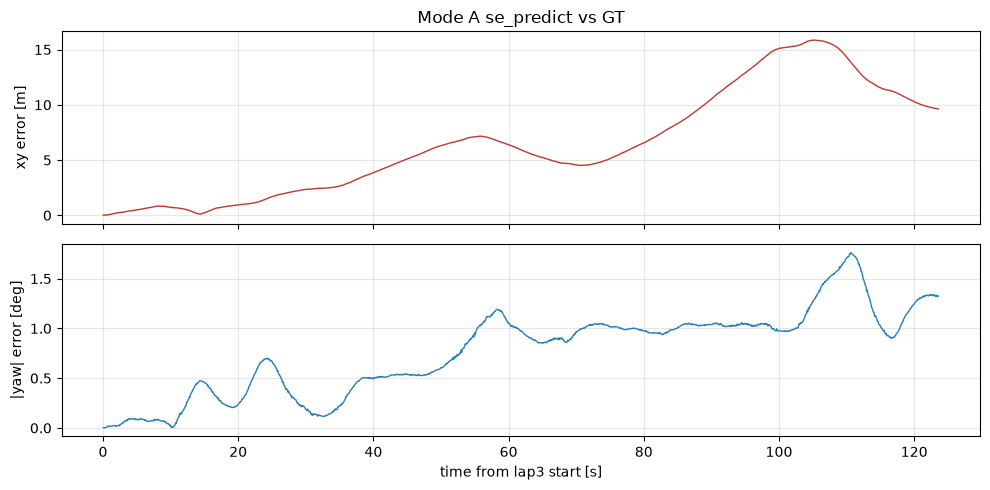

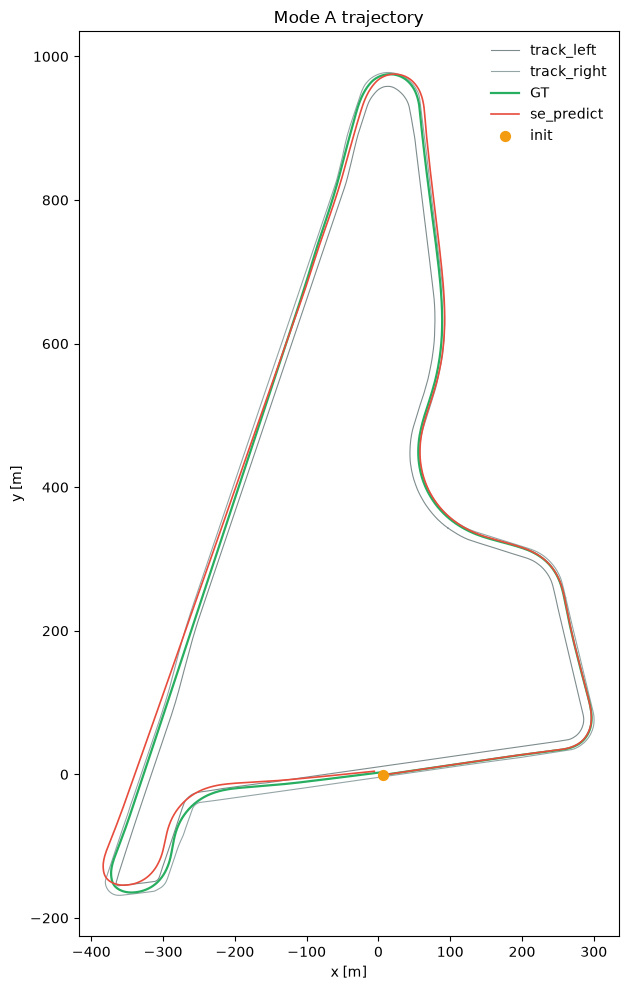

In [5]:
t_rel = (pred_a.timestamp_ns.to_numpy() - START_NS) * 1e-9

fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
axes[0].plot(t_rel, err_a, color="#c0392b", lw=1.0)
axes[0].set_ylabel("xy error [m]")
axes[0].set_title("Mode A se_predict vs GT")
axes[0].grid(True, alpha=0.3)
axes[1].plot(t_rel, np.abs(yaw_a), color="#2980b9", lw=1.0)
axes[1].set_ylabel("|yaw| error [deg]")
axes[1].set_xlabel("time from lap3 start [s]")
axes[1].grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(OUT_A / "err_vs_time.png", dpi=140, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(10, 10))
ax.plot(track_left[:, 0], track_left[:, 1], color="#7f8c8d", lw=0.8, label="track_left")
ax.plot(track_right[:, 0], track_right[:, 1], color="#95a5a6", lw=0.8, label="track_right")
ax.plot(gt_a.x, gt_a.y, color="#27ae60", lw=1.6, label="GT")
ax.plot(pred_a.x, pred_a.y, color="#e74c3c", lw=1.2, label="se_predict")
ax.scatter([x0], [y0], c="#f39c12", s=50, zorder=5, label="init")
ax.set_aspect("equal", adjustable="box")
ax.set_xlabel("x [m]"); ax.set_ylabel("y [m]")
ax.set_title("Mode A trajectory")
ax.legend(loc="best", frameon=False)
fig.tight_layout()
fig.savefig(OUT_A / "traj_vs_gt.png", dpi=140, bbox_inches="tight")
plt.show()


## 4. Mode B — EKF + three-camera sync / extrapolation / se2 + \(R(s)\)

In [6]:
pred_b, sim_b = run_mode_b_ekf(
    se,
    buckets,
    cfg,
    x0=x0,
    y0=y0,
    yaw0=yaw0,
    t0_ns=t0,
    sigma_of_s_fn=sigma_of_s,
    track_line=track_line,
)
gt_b = interp_gt(gt_all, pred_b.timestamp_ns.to_numpy())
err_b = np.hypot(pred_b.x - gt_b.x, pred_b.y - gt_b.y)
yaw_b = np.degrees(np.arctan2(np.sin(pred_b.yaw - gt_b.yaw), np.cos(pred_b.yaw - gt_b.yaw)))

sub_b = OUT_B / "submission.csv"
write_submission(pred_b, sub_b)
sim_b.to_csv(OUT_B / "sim" / "ekf_sim.csv", index=False)
print("wrote", sub_b, "n=", len(pred_b), "update_rate=", f"{sim_b.updated.mean()*100:.1f}%")
print("xy RMSE", float(np.sqrt(np.mean(err_b**2))), "median", float(np.median(err_b)))

eval_b = run_evaluate(sub_b, GT_LAP3)
print(eval_b)

met_b = metrics_vs_gt(pred_b, gt_b)
pd.Series(met_b).to_csv(OUT_B / "metrics_official.csv", header=["value"])
print(pd.Series(met_b).round(4))


wrote /Users/hbai/SchubKI/PixelRacers/query-demo/outputs/lap3/ekf_cam/submission.csv n= 1235 update_rate= 96.4%
xy RMSE 1.326985061791826 median 0.6580053695277635
poses submitted        1235   evaluated 1235
coverage (1 s bins)    100.0 %   (>= 90 % to be ranked)
position RMSE  [m]     1.327   <- SCORE (lower is better)
position median/p95    0.658 / 2.602
lateral RMSE   [m]     0.688
longitudinal RMSE [m]  1.135
yaw RMSE     [deg]     0.507
within 0.25 m          6.7 %
within 0.50 m          29.6 %
within 1.00 m          65.6 %

n_query           1235.0000
n_success         1235.0000
success_rate_%     100.0000
pos_rmse_xy_m        1.3270
lat_rmse_m           0.6875
lon_rmse_m           1.1350
yaw_rmse_deg         0.5067
within_1m_%         65.5870
pos_median_m         0.6580
pos_p95_m            2.6017
pos_rmse_sn_m        1.2826
s_rmse_m             1.0688
n_rmse_m             0.7091
track_lap_m       2976.8753
dtype: float64


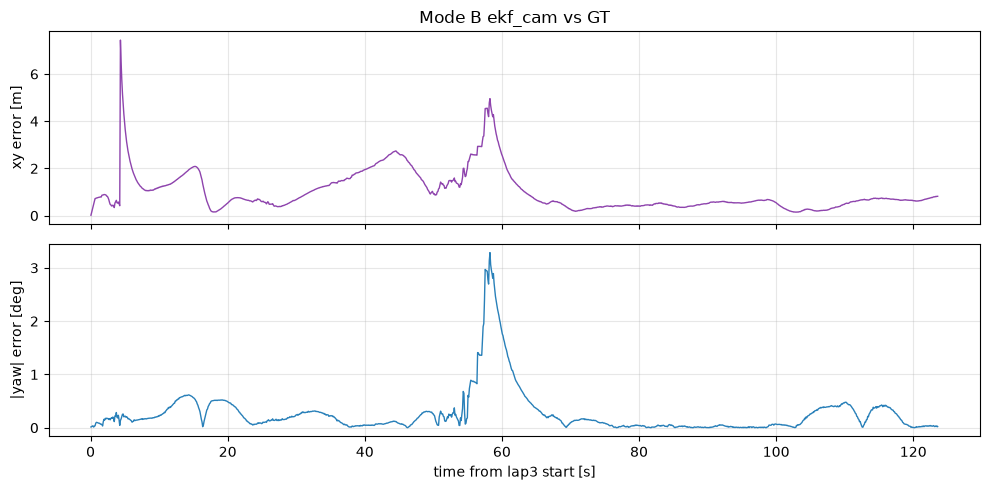

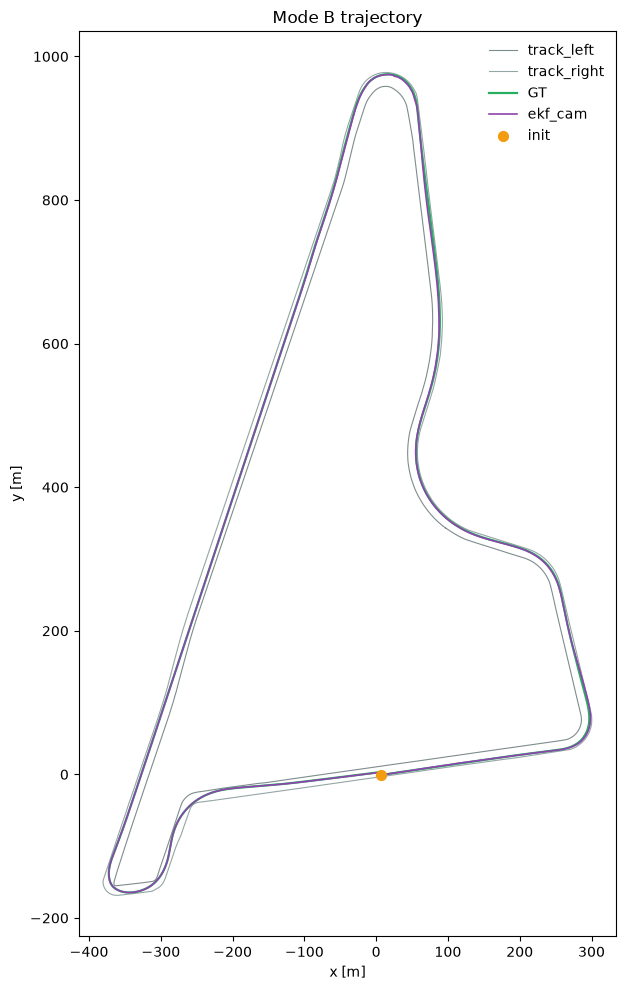

In [7]:
t_rel_b = (pred_b.timestamp_ns.to_numpy() - START_NS) * 1e-9

fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
axes[0].plot(t_rel_b, err_b, color="#8e44ad", lw=1.0)
axes[0].set_ylabel("xy error [m]")
axes[0].set_title("Mode B ekf_cam vs GT")
axes[0].grid(True, alpha=0.3)
axes[1].plot(t_rel_b, np.abs(yaw_b), color="#2980b9", lw=1.0)
axes[1].set_ylabel("|yaw| error [deg]")
axes[1].set_xlabel("time from lap3 start [s]")
axes[1].grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(OUT_B / "err_vs_time.png", dpi=140, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(10, 10))
ax.plot(track_left[:, 0], track_left[:, 1], color="#7f8c8d", lw=0.8, label="track_left")
ax.plot(track_right[:, 0], track_right[:, 1], color="#95a5a6", lw=0.8, label="track_right")
ax.plot(gt_b.x, gt_b.y, color="#27ae60", lw=1.6, label="GT")
ax.plot(pred_b.x, pred_b.y, color="#8e44ad", lw=1.2, label="ekf_cam")
ax.scatter([x0], [y0], c="#f39c12", s=50, zorder=5, label="init")
ax.set_aspect("equal", adjustable="box")
ax.set_xlabel("x [m]"); ax.set_ylabel("y [m]")
ax.set_title("Mode B trajectory")
ax.legend(loc="best", frameon=False)
fig.tight_layout()
fig.savefig(OUT_B / "traj_vs_gt.png", dpi=140, bbox_inches="tight")
plt.show()


## 5. metrics_official: SE predict / three-camera fusion / EKF

Compare all three (style aligned with `sfm_hfnet_r_lap2_lap4_s_order_lap3_loc.ipynb` §3):

| mode | Source |
|---|---|
| `se_predict` | Mode A dead reckoning |
| `fused_se2` | `loc_lap3_fused/errors_se2.csv` (three-camera ω-weighted SE(2), no process model) |
| `ekf_cam` | Mode B EKF |


=== metrics_official (se_predict | fused_se2 | ekf_cam) ===
      mode  n_query  n_success  success_rate_%  pos_rmse_xy_m  lat_rmse_m  lon_rmse_m  pos_rmse_sn_m  s_rmse_m  n_rmse_m  yaw_rmse_deg  within_1m_%  pos_median_m  pos_p95_m
se_predict     1235       1235         100.000          8.026       6.175       5.127          7.961     5.112     6.104         0.876       16.680         5.715     15.299
 fused_se2     1235       1191          96.437          4.424       2.275       3.794          4.363     3.664     2.370         0.874       72.713         0.367      8.893
   ekf_cam     1235       1235         100.000          1.327       0.688       1.135          1.283     1.069     0.709         0.507       65.587         0.658      2.602
wrote /Users/hbai/SchubKI/PixelRacers/query-demo/outputs/lap3/compare/metrics_official.csv
saved /Users/hbai/SchubKI/PixelRacers/query-demo/outputs/lap3/compare/metrics_official.png


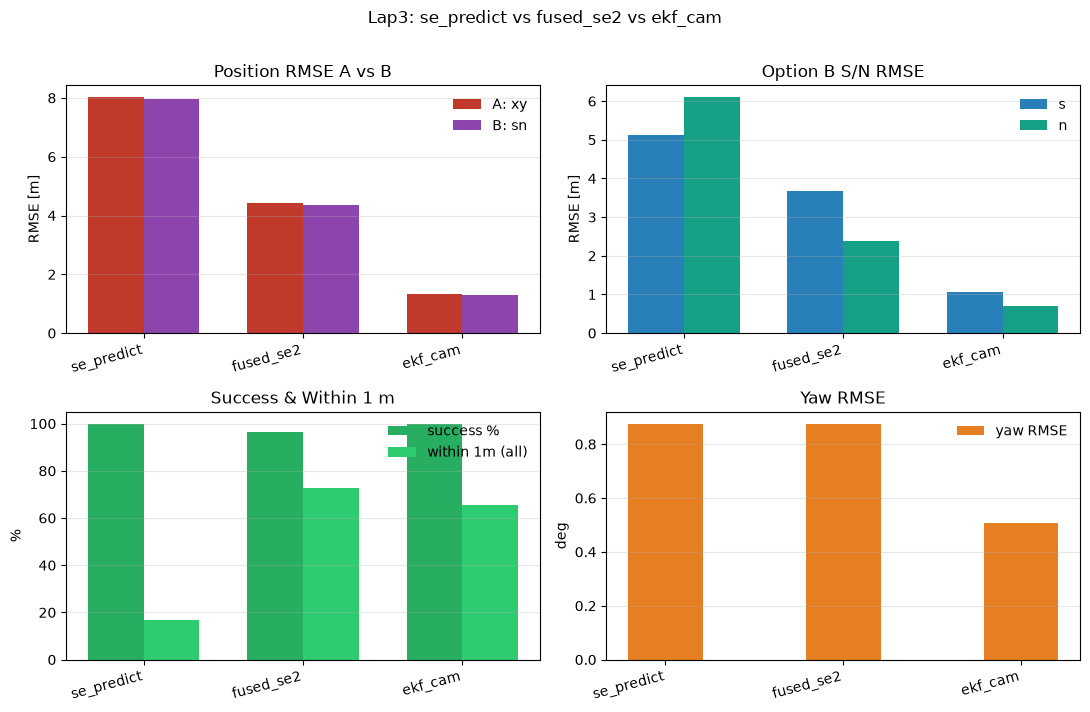

In [8]:
# --- fused_se2 (3-camera fusion, same as multi-lap notebook) ---
fuse_csv = qde.SFM_OUT / "loc_lap3_fused" / "errors_se2.csv"
df_fuse = pd.read_csv(fuse_csv)
df_fuse["stamp_ns"] = df_fuse["stamp_ns"].astype("int64")
ok_f = df_fuse["ok"].astype(bool).to_numpy()
met_fuse = qde.compute_camloc_metrics(
    stamps_ns=df_fuse["stamp_ns"].to_numpy(),
    gt_xy=np.column_stack([df_fuse["gt_x"], df_fuse["gt_y"]]),
    gt_yaw=df_fuse["gt_yaw"].to_numpy(float),
    pred_xy=np.column_stack([df_fuse["pred_x"], df_fuse["pred_y"]]),
    pred_yaw=df_fuse["pred_yaw"].to_numpy(float),
    ok=ok_f,
)
met_fuse["mode"] = "fused_se2"
met_a["mode"] = "se_predict"
met_b["mode"] = "ekf_cam"

METRIC_COLS = [
    "mode",
    "n_query",
    "n_success",
    "success_rate_%",
    "pos_rmse_xy_m",
    "lat_rmse_m",
    "lon_rmse_m",
    "pos_rmse_sn_m",
    "s_rmse_m",
    "n_rmse_m",
    "yaw_rmse_deg",
    "within_1m_%",
    "pos_median_m",
    "pos_p95_m",
]

mdf = pd.DataFrame([met_a, met_fuse, met_b])
mdf = mdf[[c for c in METRIC_COLS if c in mdf.columns]]
# stable order
order = {"se_predict": 0, "fused_se2": 1, "ekf_cam": 2}
mdf = mdf.sort_values("mode", key=lambda s: s.map(order)).reset_index(drop=True)

off_path = OUT_C / "metrics_official.csv"
mdf.to_csv(off_path, index=False)
cmp_path = OUT_C / "metrics_compare.csv"
mdf.to_csv(cmp_path, index=False)

print("=== metrics_official (se_predict | fused_se2 | ekf_cam) ===")
print(mdf.to_string(index=False, float_format=lambda x: f"{x:.3f}"))
print("wrote", off_path)

# bar charts (same layout as multi-lap notebook §3)
modes = mdf["mode"].tolist()
x = np.arange(len(modes))
w = 0.35
fig, axes = plt.subplots(2, 2, figsize=(11, 7))

ax = axes[0, 0]
ax.bar(x - w / 2, mdf["pos_rmse_xy_m"], w, label="A: xy", color="#c0392b")
ax.bar(x + w / 2, mdf["pos_rmse_sn_m"], w, label="B: sn", color="#8e44ad")
ax.set_xticks(x); ax.set_xticklabels(modes, rotation=15, ha="right")
ax.set_ylabel("RMSE [m]"); ax.set_title("Position RMSE A vs B")
ax.legend(frameon=False); ax.grid(True, axis="y", alpha=0.3)

ax = axes[0, 1]
ax.bar(x - w / 2, mdf["s_rmse_m"], w, label="s", color="#2980b9")
ax.bar(x + w / 2, mdf["n_rmse_m"], w, label="n", color="#16a085")
ax.set_xticks(x); ax.set_xticklabels(modes, rotation=15, ha="right")
ax.set_ylabel("RMSE [m]"); ax.set_title("Option B S/N RMSE")
ax.legend(frameon=False); ax.grid(True, axis="y", alpha=0.3)

ax = axes[1, 0]
ax.bar(x - w / 2, mdf["success_rate_%"], w, label="success %", color="#27ae60")
ax.bar(x + w / 2, mdf["within_1m_%"], w, label="within 1m (all)", color="#2ecc71")
ax.set_xticks(x); ax.set_xticklabels(modes, rotation=15, ha="right")
ax.set_ylabel("%"); ax.set_title("Success & Within 1 m")
ax.legend(frameon=False); ax.grid(True, axis="y", alpha=0.3)

ax = axes[1, 1]
ax.bar(x, mdf["yaw_rmse_deg"], w * 1.2, label="yaw RMSE", color="#e67e22")
ax.set_xticks(x); ax.set_xticklabels(modes, rotation=15, ha="right")
ax.set_ylabel("deg"); ax.set_title("Yaw RMSE")
ax.legend(frameon=False); ax.grid(True, axis="y", alpha=0.3)

fig.suptitle("Lap3: se_predict vs fused_se2 vs ekf_cam", y=1.01)
fig.tight_layout()
fig.savefig(OUT_C / "metrics_official.png", dpi=150, bbox_inches="tight")
print("saved", OUT_C / "metrics_official.png")
plt.show()


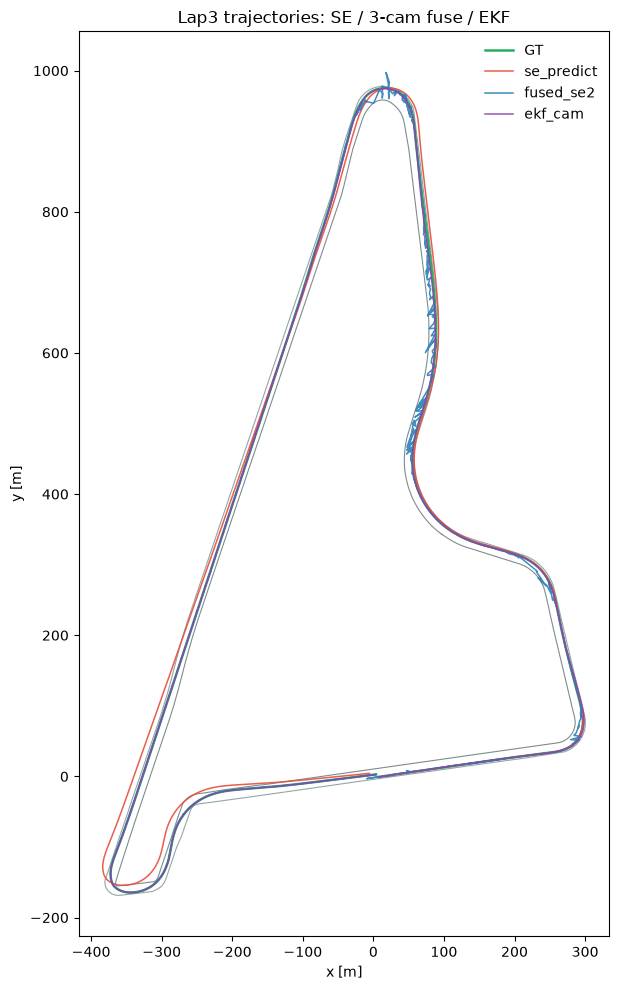

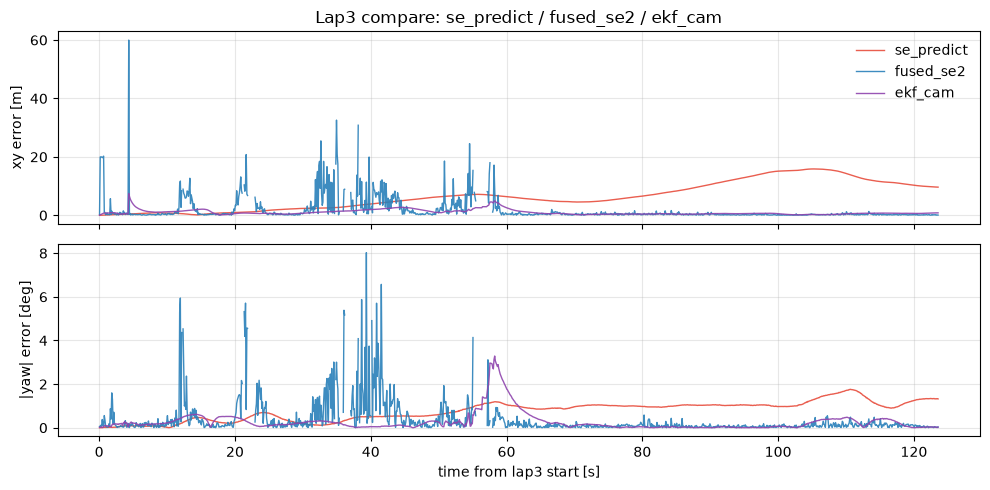

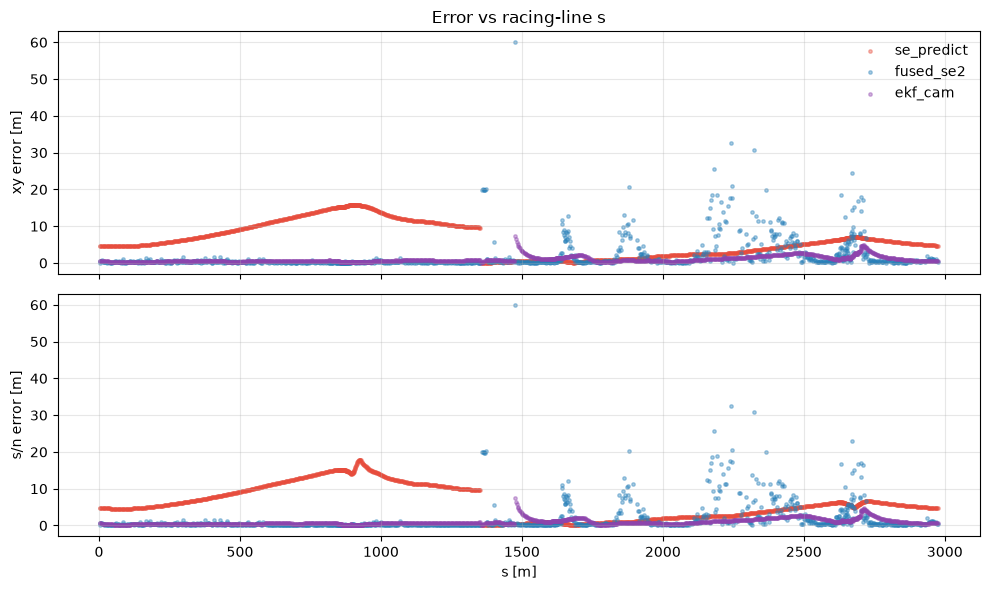

done. outputs under /Users/hbai/SchubKI/PixelRacers/query-demo/outputs/lap3
      mode  pos_rmse_xy_m  pos_rmse_sn_m  yaw_rmse_deg  within_1m_%  success_rate_%
se_predict          8.026          7.961         0.876       16.680         100.000
 fused_se2          4.424          4.363         0.874       72.713          96.437
   ekf_cam          1.327          1.283         0.507       65.587         100.000


In [9]:
# trajectories: GT + se_predict + fused_se2 + ekf_cam
pred_f = pd.DataFrame({
    "timestamp_ns": df_fuse["stamp_ns"].to_numpy(),
    "x": df_fuse["pred_x"].to_numpy(float),
    "y": df_fuse["pred_y"].to_numpy(float),
    "yaw": df_fuse["pred_yaw"].to_numpy(float),
})
# only plot successful fused poses for traj clarity
pred_f_ok = pred_f.loc[ok_f].reset_index(drop=True)
gt_f_ok = pd.DataFrame({
    "x": df_fuse.loc[ok_f, "gt_x"].to_numpy(float),
    "y": df_fuse.loc[ok_f, "gt_y"].to_numpy(float),
})

fig, ax = plt.subplots(figsize=(10, 10))
ax.plot(track_left[:, 0], track_left[:, 1], color="#7f8c8d", lw=0.8)
ax.plot(track_right[:, 0], track_right[:, 1], color="#95a5a6", lw=0.8)
ax.plot(gt_a.x, gt_a.y, color="#27ae60", lw=1.8, label="GT")
ax.plot(pred_a.x, pred_a.y, color="#e74c3c", lw=1.1, label="se_predict", alpha=0.9)
ax.plot(pred_f_ok.x, pred_f_ok.y, color="#2980b9", lw=1.1, label="fused_se2", alpha=0.9)
ax.plot(pred_b.x, pred_b.y, color="#8e44ad", lw=1.1, label="ekf_cam", alpha=0.9)
ax.set_aspect("equal", adjustable="box")
ax.set_xlabel("x [m]"); ax.set_ylabel("y [m]")
ax.set_title("Lap3 trajectories: SE / 3-cam fuse / EKF")
ax.legend(loc="best", frameon=False)
fig.tight_layout()
fig.savefig(OUT_C / "traj_vs_gt.png", dpi=140, bbox_inches="tight")
plt.show()

# err vs time (xy)
err_f = np.full(len(df_fuse), np.nan)
err_f[ok_f] = np.hypot(
    df_fuse.loc[ok_f, "pred_x"].to_numpy(float) - df_fuse.loc[ok_f, "gt_x"].to_numpy(float),
    df_fuse.loc[ok_f, "pred_y"].to_numpy(float) - df_fuse.loc[ok_f, "gt_y"].to_numpy(float),
)
t_rel_f = (df_fuse["stamp_ns"].to_numpy() - START_NS) * 1e-9

fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
axes[0].plot(t_rel, err_a, color="#e74c3c", lw=1.0, label="se_predict", alpha=0.9)
axes[0].plot(t_rel_f, err_f, color="#2980b9", lw=1.0, label="fused_se2", alpha=0.9)
axes[0].plot(t_rel_b, err_b, color="#8e44ad", lw=1.0, label="ekf_cam", alpha=0.9)
axes[0].set_ylabel("xy error [m]")
axes[0].legend(frameon=False)
axes[0].grid(True, alpha=0.3)
axes[0].set_title("Lap3 compare: se_predict / fused_se2 / ekf_cam")
axes[1].plot(t_rel, np.abs(yaw_a), color="#e74c3c", lw=1.0, alpha=0.9)
yaw_f = np.full(len(df_fuse), np.nan)
yaw_f[ok_f] = np.degrees(np.arctan2(
    np.sin(df_fuse.loc[ok_f, "pred_yaw"].to_numpy(float) - df_fuse.loc[ok_f, "gt_yaw"].to_numpy(float)),
    np.cos(df_fuse.loc[ok_f, "pred_yaw"].to_numpy(float) - df_fuse.loc[ok_f, "gt_yaw"].to_numpy(float)),
))
axes[1].plot(t_rel_f, np.abs(yaw_f), color="#2980b9", lw=1.0, alpha=0.9)
axes[1].plot(t_rel_b, np.abs(yaw_b), color="#8e44ad", lw=1.0, alpha=0.9)
axes[1].set_ylabel("|yaw| error [deg]")
axes[1].set_xlabel("time from lap3 start [s]")
axes[1].grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(OUT_C / "err_vs_time.png", dpi=140, bbox_inches="tight")
plt.show()

# err vs racing-line s
def errs_vs_s(pred, gt_at, ok_mask=None):
    if ok_mask is None:
        ok_mask = np.ones(len(pred), dtype=bool)
    ts = pred["timestamp_ns"].to_numpy(dtype=np.int64)[ok_mask]
    gx = gt_at["x"].to_numpy()[ok_mask] if "x" in gt_at.columns else gt_at.x.to_numpy()[ok_mask]
    gy = gt_at["y"].to_numpy()[ok_mask] if "y" in gt_at.columns else gt_at.y.to_numpy()[ok_mask]
    gyaw = gt_at["yaw"].to_numpy()[ok_mask] if "yaw" in gt_at.columns else gt_at.yaw.to_numpy()[ok_mask]
    px = pred["x"].to_numpy()[ok_mask]
    py = pred["y"].to_numpy()[ok_mask]
    pyaw = pred["yaw"].to_numpy()[ok_mask]
    sg, ng, _, _ = track_line.xy_to_sn(gx, gy, gyaw, ts)
    sp, np_, _, _ = track_line.xy_to_sn(px, py, pyaw, ts)
    lap = float(track_line.lap)
    sg_u = np.unwrap(sg, period=lap)
    ds = (sp - sg_u + lap / 2) % lap - lap / 2
    dn = np_ - ng
    e_xy = np.hypot(px - gx, py - gy)
    return sg, e_xy, np.hypot(ds, dn)

s_a, e_a_s, e_sn_a = errs_vs_s(pred_a, gt_a)
s_b, e_b_s, e_sn_b = errs_vs_s(pred_b, gt_b)
gt_fuse_full = pd.DataFrame({
    "x": df_fuse["gt_x"].to_numpy(float),
    "y": df_fuse["gt_y"].to_numpy(float),
    "yaw": df_fuse["gt_yaw"].to_numpy(float),
})
s_f, e_f_s, e_sn_f = errs_vs_s(pred_f, gt_fuse_full, ok_f)

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
axes[0].scatter(s_a, e_a_s, s=6, c="#e74c3c", alpha=0.4, label="se_predict")
axes[0].scatter(s_f, e_f_s, s=6, c="#2980b9", alpha=0.4, label="fused_se2")
axes[0].scatter(s_b, e_b_s, s=6, c="#8e44ad", alpha=0.4, label="ekf_cam")
axes[0].set_ylabel("xy error [m]")
axes[0].legend(frameon=False)
axes[0].grid(True, alpha=0.3)
axes[0].set_title("Error vs racing-line s")
axes[1].scatter(s_a, e_sn_a, s=6, c="#e74c3c", alpha=0.4)
axes[1].scatter(s_f, e_sn_f, s=6, c="#2980b9", alpha=0.4)
axes[1].scatter(s_b, e_sn_b, s=6, c="#8e44ad", alpha=0.4)
axes[1].set_ylabel("s/n error [m]")
axes[1].set_xlabel("s [m]")
axes[1].grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(OUT_C / "err_vs_s.png", dpi=140, bbox_inches="tight")
fig.savefig(OUT_A / "err_vs_s.png", dpi=140, bbox_inches="tight")
fig.savefig(OUT_B / "err_vs_s.png", dpi=140, bbox_inches="tight")
plt.show()

print("done. outputs under", OUT)
print(mdf[["mode", "pos_rmse_xy_m", "pos_rmse_sn_m", "yaw_rmse_deg", "within_1m_%", "success_rate_%"]].to_string(index=False, float_format=lambda x: f"{x:.3f}"))


## Output manifest

```
query-demo/outputs/lap3/
  gt_lap3.csv
  se_predict/submission.csv, metrics_official.csv, traj_vs_gt.png, err_vs_time.png
  ekf_cam/submission.csv, metrics_official.csv, traj_vs_gt.png, err_vs_time.png, sim/ekf_sim.csv
  compare/
    metrics_official.csv      # se_predict | fused_se2 | ekf_cam
    metrics_official.png      # four-panel bar chart (aligned with multi-lap notebook)
    metrics_compare.csv
    traj_vs_gt.png, err_vs_time.png, err_vs_s.png
```
